# 05. Feature Selection

Feature selection (selección de características) consiste en escoger, entre las variables predictoras construidas, las que aportan más información para pronosticar la variable objetivo. En este caso, se seleccionan cuáles rezagos y medidas móviles de volatilidad —las columnas de $X$— son más útiles para estimar el Parkinson $y$ del día $\tau$.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

In [2]:

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

In [3]:
RAIZ

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/AprendizajeSupervisado/Proyectofinal_ml_wti')

In [4]:
import numpy as np
import pandas as pd
import importlib
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest
from sklearn.ensemble import RandomForestRegressor


from sklearn.manifold import TSNE

from sklearn.preprocessing import RobustScaler
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from functools import partial
from sklearn.feature_selection import mutual_info_regression
from src import feature_extraction as fe
from src import config as cfg

In [5]:
importlib.reload(fe)

<module 'src.feature_extraction' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\AprendizajeSupervisado\\Proyectofinal_ml_wti\\src\\feature_extraction.py'>

In [6]:
PROC = RAIZ / "data" / "processed"
FIG_DIR = RAIZ / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [7]:
X = pd.read_csv(
    PROC / "fe_features_X.csv",
    index_col=0,
    parse_dates=True
)

y_df = pd.read_csv(
    PROC / "fe_features_y.csv",
    index_col=0,
    parse_dates=True
)

y = y_df.iloc[:, 0]
y.name = "WTI_park"

# Conserva solo las fechas compartidas y en el mismo orden
X, y = X.align(y, join="inner", axis=0)

print("X:", X.shape)
print("y:", y.shape)
print("Fechas:", X.index.min(), "→", X.index.max())

X: (3706, 67)
y: (3706,)
Fechas: 2010-04-07 00:00:00 → 2024-12-31 00:00:00


In [8]:
FOLDS = pd.read_csv(PROC / "folds.csv",
                    parse_dates=["train_ini", "train_fin", "val_ini", "val_fin"])

## 1. Feature Selection

Se emplea información mutua para regresión porque mide cuánto ayuda una variable a reducir la incertidumbre sobre un objetivo numérico. A diferencia de una correlación lineal, se pueden detectar asociaciones no lineales.

SelectKBest calcula el puntaje de cada característica usando solo el fold de entrenamiento y conserva las $k$ con mayor puntuación; después, el Random Forest se ajusta con esas variables.

La información mutua sirve para ordenar o filtrar variables, pero no determina por sí sola el mejor conjunto. Por eso se compara el desempeño de distintos valores de $k$ en validación temporal, usando métricas como QLIKE y MSE.

Se usa un Random Forest en cada fold para evaluar cuántas variables conviene seleccionar.

En cada iteración, el Pipeline selecciona las $k$ variables con mayor información mutua usando solo el entrenamiento del fold y ajusta un Random Forest con ellas. Después calcula el error en el periodo de validación.

Al terminar, eliges un valor de $k$ según el desempeño de validación.

In [9]:
SEED = 42
mi_score = partial(mutual_info_regression, random_state=SEED)

K_GRID = [5, 10, 15, 16,17,18,19, 20, 21,22,23,24, 25, 30, 35, 40, 45, 50, X.shape[1]]

filas = []

for k in K_GRID:
    for f in FOLDS.itertuples():
        tr = (X.index >= f.train_ini) & (X.index <= f.train_fin)
        va = (X.index >= f.val_ini) & (X.index <= f.val_fin)

        pipeline = Pipeline([
            ("seleccion", SelectKBest(score_func=mi_score, k=k)),
            ("modelo", RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=20,
                random_state=SEED,
                n_jobs=-1
            ))
        ])

        pipeline.fit(X.loc[tr], y.loc[tr])
        pred = pipeline.predict(X.loc[va]).clip(min=1e-6)
        y_val = y.loc[va]

        filas.append({
            "rep": f.rep,
            "fold": f.fold,
            "k": k,
            "mse": ((y_val - pred) ** 2).mean(),
            "qlike": (y_val / pred + np.log(pred)).mean()
        })

resultados_k = pd.DataFrame(filas)

# Resumen de cada k sobre todos los folds y repeticiones
resumen_k = (
    resultados_k.groupby("k")[["mse", "qlike"]]
    .agg(["mean", "std"])
    .round(4)
)

display(resumen_k)


mse              qlike        
         mean        std    mean     std
k                                       
5   1356.0522  2678.4470  2.8937  0.7101
10  1353.3733  2647.7832  2.8739  0.6823
15  1349.2361  2649.0690  2.8716  0.6793
16  1349.1273  2648.9883  2.8713  0.6798
17  1349.2295  2648.9541  2.8732  0.6806
18  1349.2333  2648.9807  2.8729  0.6823
19  1349.2832  2649.0381  2.8731  0.6823
20  1349.2795  2649.0568  2.8735  0.6822
21  1349.2854  2649.0856  2.8737  0.6825
22  1349.3411  2649.2292  2.8730  0.6817
23  1349.2596  2649.0784  2.8717  0.6803
24  1349.4241  2649.0687  2.8721  0.6813
25  1349.6028  2649.1171  2.8712  0.6814
30  1351.3093  2652.6255  2.8715  0.6893
35  1351.2721  2652.6831  2.8705  0.6889
40  1351.2550  2652.7246  2.8694  0.6885
45  1351.3982  2653.1042  2.8692  0.6881
50  1351.5481  2653.1399  2.8705  0.6884
67  1351.6656  2653.2780  2.8713  0.6888

Se seleccionan **\(k=16\) variables** porque este valor obtiene el menor MSE promedio (1349.13) y mantiene un QLIKE muy cercano al mínimo: 2.8713 frente a 2.8692 para \(k=45\). Como la diferencia de QLIKE es pequeña en relación con su variabilidad entre folds, usar 16 variables ofrece un buen equilibrio entre desempeño y simplicidad.

In [14]:
resumen_por_rep = (
    resultados_k.groupby(["rep", "k"])[["mse", "qlike"]]
    .mean()
    .round(4)
)

display(resumen_por_rep)

mse   qlike
rep k                    
1   5   1355.5149  2.8894
    10  1352.2397  2.8689
    15  1348.6657  2.8673
    16  1348.4940  2.8668
    17  1348.6869  2.8694
    18  1348.6266  2.8678
    19  1348.6850  2.8681
    20  1348.6768  2.8683
    21  1348.6712  2.8684
    22  1348.6950  2.8678
    23  1348.5983  2.8667
    24  1348.8890  2.8674
    25  1349.0278  2.8668
    30  1350.4946  2.8660
    35  1350.5047  2.8657
    40  1350.4716  2.8648
    45  1350.5647  2.8643
    50  1350.7048  2.8656
    67  1350.8714  2.8663
2   5   1356.5894  2.8981
    10  1354.5069  2.8789
    15  1349.8066  2.8759
    16  1349.7606  2.8758
    17  1349.7721  2.8770
    18  1349.8399  2.8780
    19  1349.8814  2.8782
    20  1349.8822  2.8787
    21  1349.8997  2.8789
    22  1349.9872  2.8782
    23  1349.9209  2.8768
    24  1349.9593  2.8768
    25  1350.1779  2.8756
    30  1352.1240  2.8770
    35  1352.0395  2.8753
    40  1352.0385  2.8739
    45  1352.2317  2.8741
    50  1352.3915  2.8755
    67  1352.4598  2.8763

In [15]:
selector_final = SelectKBest(score_func=mi_score, k=16)
selector_final.fit(X, y)

variables_seleccionadas = X.columns[selector_final.get_support()].tolist()
print("Variables seleccionadas:")
print(variables_seleccionadas)

Variables seleccionadas:
['park_lag1', 'park_lag2', 'park_lag3', 'park_lag4', 'park_lag5', 'park_lag6', 'park_lag7', 'park_lag8', 'park_lag9', 'park_lag18', 'vol_r_5', 'park_media_5', 'vol_r_21', 'park_media_21', 'vol_r_63', 'park_media_63']


In [16]:
ranking_final = pd.DataFrame({
    "variable": X.columns,
    "informacion_mutua": selector_final.scores_
}).sort_values("informacion_mutua", ascending=False)

In [17]:
ranking_final.head(16)

,variable,informacion_mutua
61,park_media_5,0.330267
63,park_media_21,0.320574
65,park_media_63,0.265542
62,vol_r_21,0.265402
64,vol_r_63,0.225226
5,park_lag2,0.224440
2,park_lag1,0.206376
60,vol_r_5,0.196525
8,park_lag3,0.192470
14,park_lag5,0.180865


In [22]:
K_FINAL = 16

In [23]:
MI_FOLD = []
for f in FOLDS.itertuples():
    tr = (X.index >= f.train_ini) & (X.index <= f.train_fin)
    sel = SelectKBest(score_func=mi_score, k=K_FINAL if "K_FINAL" in globals() else 16).fit(X.loc[tr], y.loc[tr])
    MI_FOLD.append(pd.Series(sel.scores_, index=X.columns, name=f"R{f.rep}·F{f.fold}"))

mi_por_fold = pd.concat(MI_FOLD, axis=1)          # filas = variables, columnas = folds
display(mi_por_fold.round(3).head())

,R1·F1,R1·F2,R1·F3,R1·F4,R1·F5,R2·F1,R2·F2,R2·F3,R2·F4,R2·F5
r2_lag1,0.045,0.075,0.079,0.100,0.094,0.050,0.075,0.083,0.097,0.097
absr_lag1,0.086,0.124,0.118,0.126,0.121,0.091,0.124,0.122,0.127,0.127
park_lag1,0.193,0.240,0.224,0.233,0.220,0.195,0.238,0.231,0.228,0.230
r2_lag2,0.075,0.086,0.086,0.088,0.085,0.070,0.088,0.087,0.085,0.092
absr_lag2,0.066,0.101,0.098,0.094,0.093,0.060,0.093,0.105,0.099,0.090


## 2. TSNE

t-SNE (*t-distributed Stochastic Neighbor Embedding*) es una técnica de reducción de dimensionalidad que transforma observaciones descritas por muchas variables en un mapa de dos dimensiones. En este análisis se aplicará a las 16 características seleccionadas para visualizar si los días con patrones parecidos de retornos y volatilidad quedan cerca y si esos grupos se relacionan con niveles similares de Parkinson. El gráfico sirve para explorar agrupamientos y diferencias en los datos; sus ejes no tienen unidades ni representan características específicas, y la visualización no demuestra por sí sola que esos grupos existan en la población o que el modelo vaya a pronosticar bien.

In [18]:


# Subconjunto con las 20 variables seleccionadas
X_sel = X[variables_seleccionadas].copy()
y_sel = y.loc[X_sel.index]

# Escalado robusto antes de calcular distancias
escalador = RobustScaler()
X_escalado = escalador.fit_transform(X_sel)

# Proyección a dos dimensiones
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1000,
    random_state=SEED
)

coordenadas = tsne.fit_transform(X_escalado)

tsne_df = pd.DataFrame(
    coordenadas,
    index=X_sel.index,
    columns=["t-SNE 1", "t-SNE 2"]
)
tsne_df["Parkinson"] = y_sel



In [19]:
tsne_df

,t-SNE 1,t-SNE 2,Parkinson
Date,,,
2010-04-07,-43.720531,-7.470405,1.061799
2010-04-08,-42.220463,-24.251789,1.119836
2010-04-09,-37.991474,-17.343536,2.512998
2010-04-12,-45.581528,-14.824743,1.329691
2010-04-13,-49.446880,-5.679409,1.888898
...,...,...,...
2024-12-24,-40.645851,15.700455,0.845292
2024-12-26,-39.807468,15.930829,1.482612
2024-12-27,-41.074387,16.315556,1.259815


t-SNE es una técnica de visualización que proyecta las 26 variables seleccionadas a dos dimensiones para representar cada día como un punto en el gráfico. Los puntos cercanos corresponden, aproximadamente, a días con patrones similares en sus características; el color indica el nivel de Parkinson de ese día.

Los ejes t-SNE no representan variables específicas ni se usan como entradas del Random Forest: la técnica sirve para explorar visualmente los datos, no para evaluar por sí sola la capacidad predictiva del modelo.

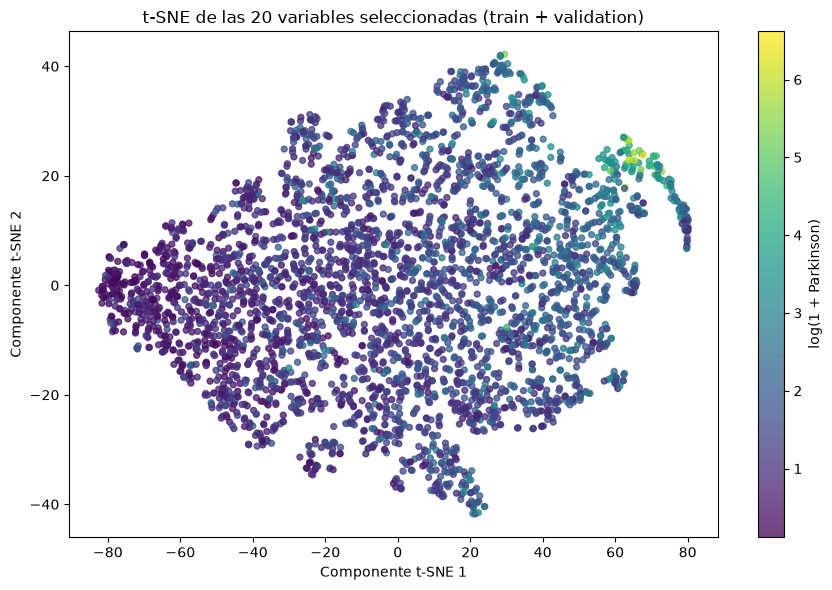

In [21]:
# El color representa el nivel del Parkinson del día objetivo
plt.figure(figsize=(9, 6))
puntos = plt.scatter(
    tsne_df["t-SNE 1"],
    tsne_df["t-SNE 2"],
    c=np.log1p(tsne_df["Parkinson"]),
    cmap="viridis",
    s=18,
    alpha=0.75
)
plt.colorbar(puntos, label="log(1 + Parkinson)")
plt.title("t-SNE de las 20 variables seleccionadas (train + validation)")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.tight_layout()
plt.show()

En la gráfica, cada punto representa un día y su color corresponde a $\ln(1+\text{Parkinson}_t)$, calculado con el logaritmo natural, donde $\text{Parkinson}_t$ es la varianza diaria estimada a partir del máximo y el mínimo del WTI expresado en $\%^{2}$ y la variable objetivo del Random Forest. 
La transformación logarítmica se aplica solo para colorear la visualización; comprime los valores altos y conserva su orden. 

Por eso, el morado indica Parkinson bajo, el azul y el verde valores intermedios, y el amarillo valores altos. 

Se puede observar en la gráfica, que en la zona izquierda predominan los valores bajos de color morado; hacia el centro  se mezclan valores bajos e intermedios, con algunos altos de colores morado y verde oscuro y a la derecha predominan los valores altos de color amarillo y verde claro. Esto sugiere una asociación parcial entre los patrones de las características y la volatilidad, pero no una separación nítida entre sus niveles.

### 3. Guardar

In [24]:
import json

K_FINAL = 16
FS_DIR = PROC / "feature_selection"
FS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Configuración de la selección (lo que usa el Random Forest)
config_fs = {
    "metodo": "SelectKBest con información mutua (mutual_info_regression)",
    "random_state": SEED,
    "k": K_FINAL,
    "criterio_k": "menor MSE promedio en los 10 folds, con QLIKE cercana al mínimo",
    "nota": ("La selección se recalcula dentro de cada fold con su entrenamiento. "
             "variables_desarrollo es solo descriptiva (ajuste con todo 2010-2024)."),
    "variables_desarrollo": variables_seleccionadas,
}
(FS_DIR / "fs_config.json").write_text(json.dumps(config_fs, indent=4, ensure_ascii=False),
                                       encoding="utf-8")

# 2. Búsqueda de k (errores por fold y resumen)
resultados_k.to_csv(FS_DIR / "fs_resultados_k_por_fold.csv", index=False)
resumen_k.to_csv(FS_DIR / "fs_resumen_k.csv")

# 3. Ranking de información mutua con todo el desarrollo (descriptivo)
ranking_final.to_csv(FS_DIR / "fs_ranking_desarrollo.csv", index=False)

# 4. Información mutua por fold (la reutiliza Optuna)
mi_por_fold.to_csv(FS_DIR / "fs_mi_por_fold.csv")

# 5. Coordenadas del t-SNE
tsne_df.to_csv(FS_DIR / "fs_tsne_coordenadas.csv")

print("Guardado en", FS_DIR)
for p in sorted(FS_DIR.iterdir()):
    print(" -", p.name)

Guardado en c:\Users\ASUS\Desktop\Maestria IA USFQ\AprendizajeSupervisado\Proyectofinal_ml_wti\data\processed\feature_selection
 - fs_config.json
 - fs_mi_por_fold.csv
 - fs_ranking_desarrollo.csv
 - fs_resultados_k_por_fold.csv
 - fs_resumen_k.csv
 - fs_tsne_coordenadas.csv
